# Otel Rezervasyon İptal Tahmini — Model Eğitimi ve Değerlendirme
---
**Hasan İNCİLER** · 250184009

Bu notebook'ta 1. aşamada incelediğim veri setiyle model eğitiyorum. Yaptıklarım:

1. veriyi yükleme ve temizleme
2. eğitim / test ayrımı
3. ölçeklendirme
4. beş modelin karşılaştırılması
5. en iyi modelin değerlendirilmesi ve karmaşıklık matrisi
6. eşik denemesi

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("kütüphaneler yüklendi")

kütüphaneler yüklendi


## 1. Veriyi yükleme ve temizleme

1\. aşamadaki adımları burada tekrar yapıyorum. Farklı olarak önce birebir aynı olan satırları siliyorum.

In [2]:
# veri seti (1. aşamadaki dosyanın aynısı)
VERI_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(VERI_URL)
print("ham veri:", df.shape)

# birebir aynı olan satırlar
print("tekrar eden satır sayısı:", df.duplicated().sum())
df = df.drop_duplicates()
print("tekrarlar silindikten sonra:", df.shape)

ham veri: (119390, 32)
tekrar eden satır sayısı: 31994


tekrarlar silindikten sonra: (87396, 32)


Tekrar eden satırları silmemin sebebi: aynı satır hem eğitim hem test verisine düşerse model o satırı
zaten görmüş olur ve test sonucu olduğundan iyi çıkar.

In [3]:
# 1. aşamadaki kararlar
# company %94 boş, reservation_status ve reservation_status_date iptal sonucunu gösteriyor (sızıntı)
df = df.drop(columns=["company", "reservation_status", "reservation_status_date"])

# agent boşsa acente yok demek -> 0, children sadece birkaç satırda boş -> 0
df["agent"] = df["agent"].fillna(0)
df["children"] = df["children"].fillna(0)

# aylar sıralı olduğu için 1-12 arası sayıya çeviriyoruz
aylar = {"January": 1, "February": 2, "March": 3, "April": 4, "May": 5, "June": 6,
         "July": 7, "August": 8, "September": 9, "October": 10, "November": 11, "December": 12}
df["arrival_date_month"] = df["arrival_date_month"].map(aylar)

print("boyut:", df.shape)
print(f"iptal oranı: %{df['is_canceled'].mean() * 100:.1f}")

boyut: (87396, 29)
iptal oranı: %27.5


## 2. Eğitim ve test verisi

Verinin %80'i eğitime, %20'si teste ayrılıyor. `stratify=y` sayesinde iptal oranı iki tarafta da aynı kalıyor,
`random_state=42` ile her çalıştırmada aynı ayrım geliyor.

In [4]:
y = df["is_canceled"]
X = df.drop(columns=["is_canceled"])

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Eğitim:", X_egitim.shape, "| Test:", X_test.shape)
print(f"iptal oranı -> eğitim: %{y_egitim.mean() * 100:.1f} | test: %{y_test.mean() * 100:.1f}")

Eğitim: (69916, 28) | Test: (17480, 28)
iptal oranı -> eğitim: %27.5 | test: %27.5


### country sütunu

Derste gördüğümüz kural: boşları doldururken kullanılan değer **eğitim verisinden** hesaplanmalı.
Bu yüzden en sık ülkeyi ve ülkelerin görülme oranlarını sadece eğitim verisinden alıyorum.

In [5]:
X_egitim = X_egitim.copy()
X_test = X_test.copy()

# en sık görülen ülke (sadece eğitimden)
ulke_modu = X_egitim["country"].mode()[0]
X_egitim["country"] = X_egitim["country"].fillna(ulke_modu)
X_test["country"] = X_test["country"].fillna(ulke_modu)

# frekans kodlama: her ülke eğitim verisindeki görülme oranıyla değişiyor
ulke_frekans = X_egitim["country"].value_counts(normalize=True)
X_egitim["country_frekans"] = X_egitim["country"].map(ulke_frekans)
X_test["country_frekans"] = X_test["country"].map(ulke_frekans).fillna(0)   # eğitimde olmayan ülke -> 0

X_egitim = X_egitim.drop(columns=["country"])
X_test = X_test.drop(columns=["country"])
print("en sık ülke:", ulke_modu)

en sık ülke: PRT


### Kategorik sütunlar

Kalan metin sütunlarına one-hot encoding yapıyorum. Test verisinin sütunlarını eğitimdekiyle aynı hale
getirmek için `reindex` kullanıyorum (6. haftadaki form örneğindeki gibi).

In [6]:
kategorik = X_egitim.select_dtypes(include=["object", "string"]).columns.tolist()
print("one-hot yapılacak sütunlar:", kategorik)

X_egitim = pd.get_dummies(X_egitim, columns=kategorik, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=kategorik, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_egitim.columns, fill_value=0)

print("Eğitim:", X_egitim.shape, "| Test:", X_test.shape)

one-hot yapılacak sütunlar: ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']


Eğitim: (69916, 60) | Test: (17480, 60)


## 3. Ölçeklendirme

`StandardScaler` her sütunu ortalaması 0, standart sapması 1 olacak şekilde dönüştürüyor.
Ölçekleyici **sadece eğitim verisine fit ediliyor**, test verisi aynı kuralla dönüştürülüyor.
Lojistik regresyon ve KNN ölçekli veriyle, ağaç modelleri ölçeksiz veriyle eğitilecek.

In [7]:
olcekleyici = StandardScaler()
olcekleyici.fit(X_egitim)                        # sadece eğitimden öğren
X_egitim_olc = olcekleyici.transform(X_egitim)
X_test_olc = olcekleyici.transform(X_test)       # testi aynı kuralla dönüştür

# kontrol: ölçekleyicinin öğrendiği ortalama, eğitim verisinin ortalaması mı?
i = list(X_egitim.columns).index("lead_time")
print("lead_time ortalaması (eğitim verisi):", round(X_egitim["lead_time"].mean(), 2))
print("ölçekleyicinin öğrendiği ortalama  :", round(olcekleyici.mean_[i], 2))
print("ölçeklendikten sonra ortalama      :", round(X_egitim_olc[:, i].mean(), 4))

lead_time ortalaması (eğitim verisi): 79.83
ölçekleyicinin öğrendiği ortalama  : 79.83
ölçeklendikten sonra ortalama      : 0.0


## 4. Model yarışması

8\. haftadaki gibi beş modeli aynı eğitim / test ayrımıyla deniyorum.

In [8]:
def metrikler(gercek, tahmin):
    # accuracy, precision, recall, f1 (3 basamak)
    return [round(accuracy_score(gercek, tahmin), 3), round(precision_score(gercek, tahmin), 3),
            round(recall_score(gercek, tahmin), 3), round(f1_score(gercek, tahmin), 3)]

modeller = {
    "Lojistik Regresyon": LogisticRegression(max_iter=5000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Karar Ağacı": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),   # 100 ağaç
}
olcekli_modeller = ["Lojistik Regresyon", "KNN"]   # bu ikisi ölçekli veriyle eğitiliyor

sonuclar = {}
for ad, model in modeller.items():
    if ad in olcekli_modeller:
        model.fit(X_egitim_olc, y_egitim)
        tahmin = model.predict(X_test_olc)
    else:
        model.fit(X_egitim, y_egitim)
        tahmin = model.predict(X_test)
    sonuclar[ad] = metrikler(y_test, tahmin)
    print(ad, "eğitildi")

tablo = pd.DataFrame(sonuclar, index=["Accuracy", "Precision", "Recall", "F1"]).T
tablo

Lojistik Regresyon eğitildi


KNN eğitildi


Karar Ağacı eğitildi
Naive Bayes eğitildi


Random Forest eğitildi


,Accuracy,Precision,Recall,F1
Lojistik Regresyon,0.783,0.659,0.438,0.526
KNN,0.802,0.656,0.593,0.623
Karar Ağacı,0.791,0.617,0.633,0.625
Naive Bayes,0.626,0.409,0.806,0.542
Random Forest,0.849,0.767,0.650,0.704


### Hangi metriğe göre seçmeli?

Derste kanser örneğinde Recall'a göre sıralamıştık, çünkü tümörü kaçırmak çok tehlikeliydi.
Otelde ise iki hata da zarar veriyor:

- **iptali kaçırmak (FN):** otel odayı boş bekletir, para kaybeder
- **yanlış alarm (FP):** otel gelecek müşterinin odasını başkasına da satar, müşteri gelince oda kalmaz

Bu yüzden ikisini dengeleyen **F1**'e göre sıralıyorum. Recall'a göre sıralasaydım Naive Bayes seçilirdi,
ama onun precision değeri çok düşük, yani çok fazla yanlış alarm veriyor.

                    Accuracy  Precision  Recall     F1
Random Forest          0.849      0.767   0.650  0.704
Karar Ağacı            0.791      0.617   0.633  0.625
KNN                    0.802      0.656   0.593  0.623
Naive Bayes            0.626      0.409   0.806  0.542
Lojistik Regresyon     0.783      0.659   0.438  0.526

en iyi model: Random Forest


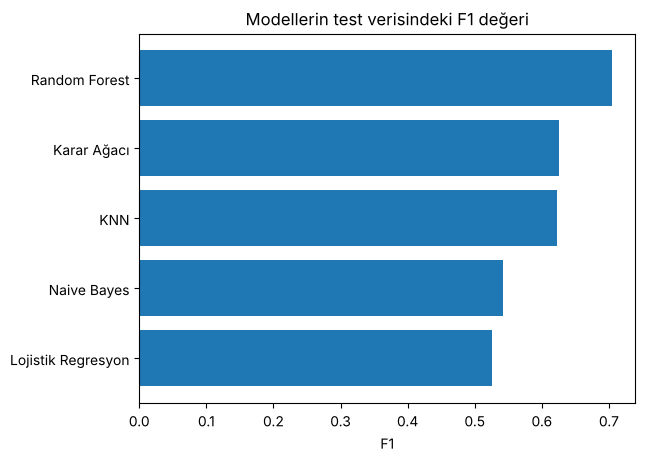

In [9]:
tablo = tablo.sort_values(["F1", "Recall"], ascending=False)
print(tablo)

en_iyi = tablo.index[0]
print("\nen iyi model:", en_iyi)

plt.barh(tablo.index[::-1], tablo["F1"][::-1])
plt.title("Modellerin test verisindeki F1 değeri")
plt.xlabel("F1")
plt.show()

## 5. En iyi model: Random Forest

Eğitimde kullanılan temel parametreler: `n_estimators=100` (100 karar ağacı), `random_state=42`.
Diğer parametreler varsayılan değerinde (`criterion="gini"`, `max_depth=None`).

In [10]:
rf = modeller[en_iyi]
tahmin = rf.predict(X_test)

print("Accuracy, Precision, Recall, F1:", metrikler(y_test, tahmin))
print()
print(classification_report(y_test, tahmin, target_names=["iptal edilmedi", "iptal edildi"]))

Accuracy, Precision, Recall, F1: [0.849, 0.767, 0.65, 0.704]

                precision    recall  f1-score   support

iptal edilmedi       0.87      0.93      0.90     12675
  iptal edildi       0.77      0.65      0.70      4805

      accuracy                           0.85     17480
     macro avg       0.82      0.79      0.80     17480
  weighted avg       0.84      0.85      0.85     17480



[[11726   949]
 [ 1682  3123]]


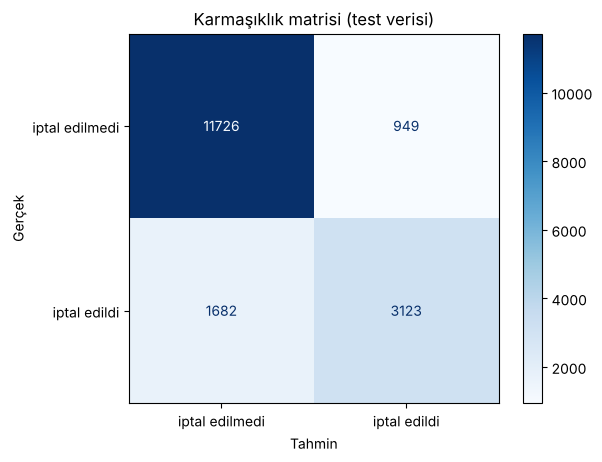

doğru bilinen 'iptal edilmedi' (TN): 11726
yanlış alarm (FP)                  : 949
kaçırılan iptal (FN)               : 1682
doğru bilinen 'iptal edildi' (TP)  : 3123


In [11]:
matris = confusion_matrix(y_test, tahmin)
print(matris)

ConfusionMatrixDisplay(matris, display_labels=["iptal edilmedi", "iptal edildi"]).plot(cmap="Blues")
plt.title("Karmaşıklık matrisi (test verisi)")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.savefig("karmasiklik_matrisi.png")
plt.show()

tn, fp, fn, tp = matris.ravel()
print("doğru bilinen 'iptal edilmedi' (TN):", tn)
print("yanlış alarm (FP)                  :", fp)
print("kaçırılan iptal (FN)               :", fn)
print("doğru bilinen 'iptal edildi' (TP)  :", tp)

**Matrisin yorumu:** Model iptal edilmeyen rezervasyonları büyük oranda doğru biliyor. En çok karışan durum,
**iptal edilen rezervasyonların "iptal edilmedi" sanılması (FN)**. Yanlış alarm (FP) sayısı bundan daha az.
Yani model "iptal edilecek" derken çoğunlukla haklı (precision yüksek), ama iptallerin bir kısmını kaçırıyor (recall daha düşük).
Veride iptal edilmeyen rezervasyonlar daha fazla olduğu için model o sınıfa doğru kayıyor.

## 6. Eşiği değiştirmek

7\. haftada gördüğümüz gibi model bir olasılık veriyor ve 0.5'in üstünü "iptal" sayıyor.
Eşiği düşürünce model daha kolay "iptal edilecek" diyor. Kaçırılan iptalleri azaltmak için 0.4 ve 0.3'ü deniyorum.

In [12]:
olasiliklar = rf.predict_proba(X_test)[:, 1]

esik_sonuclari = {"eşik 0.5 (varsayılan)": metrikler(y_test, tahmin)}   # yukarıdaki predict sonucu
for esik in [0.4, 0.3]:
    tahmin_esik = (olasiliklar >= esik).astype(int)
    esik_sonuclari[f"eşik {esik}"] = metrikler(y_test, tahmin_esik)

print(pd.DataFrame(esik_sonuclari, index=["Accuracy", "Precision", "Recall", "F1"]).T)

                       Accuracy  Precision  Recall     F1
eşik 0.5 (varsayılan)     0.849      0.767   0.650  0.704
eşik 0.4                  0.844      0.700   0.759  0.728
eşik 0.3                  0.819      0.626   0.853  0.722


Eşik düştükçe recall artıyor, precision düşüyor. F1'in en yüksek olduğu eşik 0.4. Otel için kaçırılan
iptal daha pahalıysa 0.4 seçilebilir. Raporda ana sonuç olarak varsayılan eşik (0.5) kullanıldı.

## 7. Hangi sütunlar daha önemli?

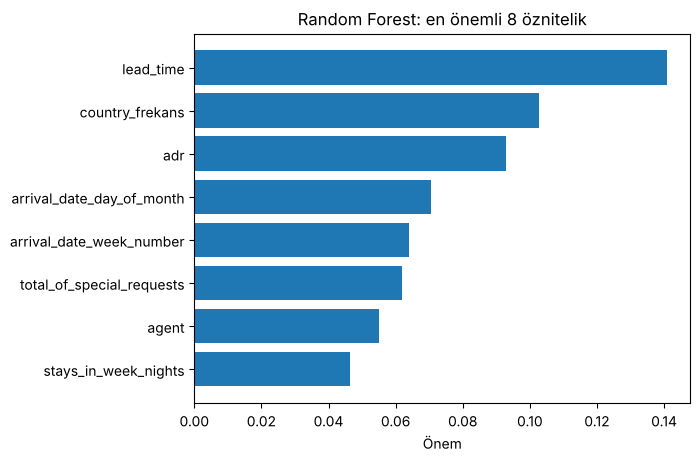

In [13]:
onem = pd.Series(rf.feature_importances_, index=X_egitim.columns).sort_values().tail(8)

plt.barh(onem.index, onem.values)
plt.title("Random Forest: en önemli 8 öznitelik")
plt.xlabel("Önem")
plt.show()

En önemli sütun `lead_time`, yani rezervasyonun giriş tarihinden kaç gün önce yapıldığı.
1\. aşamadaki grafiklerde de erken yapılan rezervasyonların daha çok iptal edildiğini görmüştük.

## Sonuç

- Tekrar eden satırlar silindi, veri %80 eğitim / %20 test olarak ayrıldı (`stratify=y`, `random_state=42`).
- `StandardScaler` sadece eğitim verisine fit edildi.
- Beş model denendi, F1'e göre en iyi model **Random Forest** oldu.
- 1\. aşamada hedef olarak F1 > %80 yazmıştım, bu hedefe ulaşılamadı. Tekrar eden satırlar silinmeseydi
  sonuç daha yüksek çıkardı ama o sonuç gerçeği göstermezdi.